tensor([[ 1.5502, -0.4005],
        [ 0.0422,  0.3740],
        [ 0.7261, -0.4288],
        [-1.0121,  0.2481],
        [-0.8756,  0.2589]]) tensor([1., 1., 1., 0., 0.])


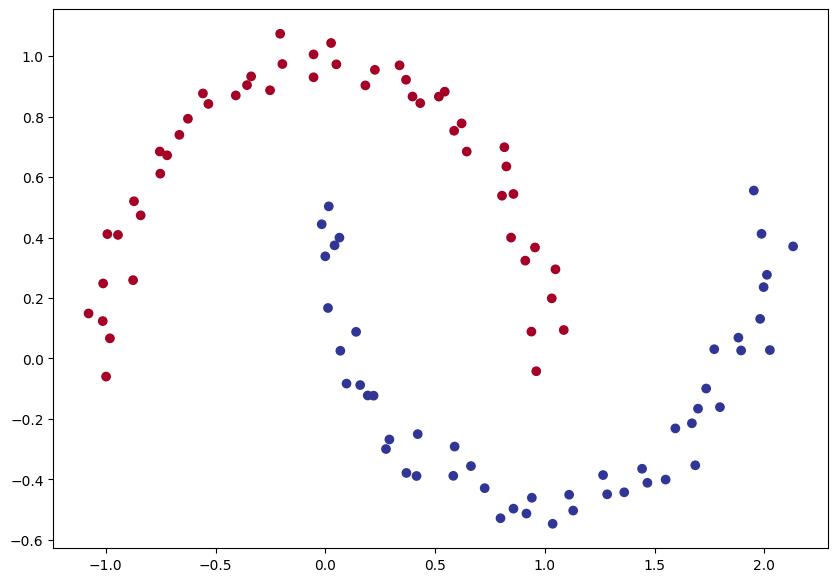

In [85]:
from sklearn.datasets import make_moons
import torch
from torch import nn
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from pathlib import Path
import requests
import numpy as np

n_samples = 100
num_features = 2
num_classes = 3
random_seed = 42

# Create the multi-class moons figure
X_moon, y_moon = make_moons(n_samples,
                   noise=0.05,
                   shuffle = True,
                   random_state=random_seed)
# print(f"shape of X_moon is: {X_moon.shape}")
# print(f"shape of y_moon is: {y_moon.shape}")

# Turn data into tensors
X_moon = torch.from_numpy(X_moon).type(torch.float)
y_moon = torch.from_numpy(y_moon).type(torch.float)
print(X_moon[:5], y_moon[:5])

# split data into train and test set
X_moon_train, X_moon_test, y_moon_train, y_moon_test = train_test_split(X_moon,
                                                                 y_moon,
                                                                 test_size=0.2,
                                                                 random_state=random_seed)

#Plot the data
plt.figure(figsize=(10, 7))
plt.scatter(X_moon[:, 0], X_moon[:, 1], c=y_moon, cmap=plt.cm.RdYlBu);

In [86]:
if Path("helper_functions.py").is_file():
    print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

from helper_functions import plot_predictions, plot_decision_boundary

helper_functions.py already exists, skipping download


In [87]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [88]:
class MakeMoonV1(nn.Module):
    def __init__(self, input_features, output_features, hidden_units=10):
        super().__init__()
        self.linear_layer_stack = nn.Sequential(
            nn.Linear(in_features=input_features, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=output_features)
        )

    def forward(self, x):
         return self.linear_layer_stack(x)

model_1 = MakeMoonV1(input_features=num_features,
                    output_features=num_classes,
                    hidden_units=10).to(device)

model_1

MakeMoonV1(
  (linear_layer_stack): Sequential(
    (0): Linear(in_features=2, out_features=10, bias=True)
    (1): ReLU()
    (2): Linear(in_features=10, out_features=10, bias=True)
    (3): ReLU()
    (4): Linear(in_features=10, out_features=3, bias=True)
  )
)

In [89]:
# Setting up the optimizer and the loss function
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_1.parameters(),
                           lr = 0.01)

def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc    

In [90]:
# Creatng the training and testing loop for the custom model_1
X_moon_train, X_moon_test = X_moon_train.to(device), X_moon_test.to(device)
y_moon_train, y_moon_test = y_moon_train.to(device), y_moon_test.to(device)

torch.manual_seed(42)

# set Up parameters
epochs = 1000 # tuning the epoch to a lower count first

for epoch in range(epochs):
    # put the model in train mode
    model_1.train()

    y_moon_train = y_moon_train.type(torch.long)
    y_moon_test = y_moon_test.type(torch.long)


    ### TRAINING

    # forward pass
    y_logits = model_1(X_moon_train) # The model oput raw logits
    y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1)
    # print(y_logits)

    # Calculate the loss and the accuracy
    loss = loss_fn(y_logits, y_moon_train)
    acc = accuracy_fn(y_true=y_moon_train,
                y_pred=y_pred)

    # Optimize the zero_grad
    optimizer.zero_grad()

    # Loss backward
    loss.backward() # this is the backpropagation value

    # optimizer step
    optimizer.step() # this is the gradient_descent algorithm


    ### TESTING
    model_1.eval()

    with torch.inference_mode():
        test_logits_pred = model_1(X_moon_test)
        test_pred = torch.softmax(test_logits_pred, dim=1).argmax(dim=1)

        # calculate the loss and accuracy
        test_loss = loss_fn(test_logits_pred, y_moon_test)
        test_acc = accuracy_fn(y_true=y_moon_test,
                              y_pred=test_pred)

    if epoch % 10 == 0:
         print(f"Epoch: {epoch} | Loss: {loss:.5f}, Acc: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.2f}%")

Epoch: 0 | Loss: 1.25508, Acc: 0.00% | Test Loss: 1.28981, Test Acc: 0.00%
Epoch: 10 | Loss: 1.21720, Acc: 0.00% | Test Loss: 1.25525, Test Acc: 0.00%
Epoch: 20 | Loss: 1.18386, Acc: 0.00% | Test Loss: 1.22484, Test Acc: 0.00%
Epoch: 30 | Loss: 1.15422, Acc: 0.00% | Test Loss: 1.19773, Test Acc: 0.00%
Epoch: 40 | Loss: 1.12768, Acc: 31.25% | Test Loss: 1.17345, Test Acc: 20.00%
Epoch: 50 | Loss: 1.10374, Acc: 55.00% | Test Loss: 1.15154, Test Acc: 30.00%
Epoch: 60 | Loss: 1.08200, Acc: 55.00% | Test Loss: 1.13165, Test Acc: 30.00%
Epoch: 70 | Loss: 1.06213, Acc: 55.00% | Test Loss: 1.11349, Test Acc: 30.00%
Epoch: 80 | Loss: 1.04387, Acc: 55.00% | Test Loss: 1.09682, Test Acc: 30.00%
Epoch: 90 | Loss: 1.02703, Acc: 55.00% | Test Loss: 1.08148, Test Acc: 30.00%
Epoch: 100 | Loss: 1.01145, Acc: 55.00% | Test Loss: 1.06729, Test Acc: 30.00%
Epoch: 110 | Loss: 0.99695, Acc: 55.00% | Test Loss: 1.05412, Test Acc: 30.00%
Epoch: 120 | Loss: 0.98342, Acc: 55.00% | Test Loss: 1.04185, Test Acc:

In [91]:
# Making predictions with the trained model
model_1.eval()
with torch.inference_mode():
 y_logits = model_1(X_moon_test)
 y_pred_probs = torch.softmax(y_logits, dim=1)
 y_preds = y_pred_probs.argmax(dim=1)
    
# Compare first 10 model preds and test labels
print(f"Predictions: {y_preds[:10]}\nLabels: {y_moon_test[:10]}")
print(f"Test accuracy: {accuracy_fn(y_true=y_moon_test, y_pred=y_preds)}%")

Predictions: tensor([0, 0, 1, 0, 0, 0, 0, 1, 0, 1])
Labels: tensor([0, 0, 1, 0, 0, 0, 0, 1, 0, 1])
Test accuracy: 100.0%


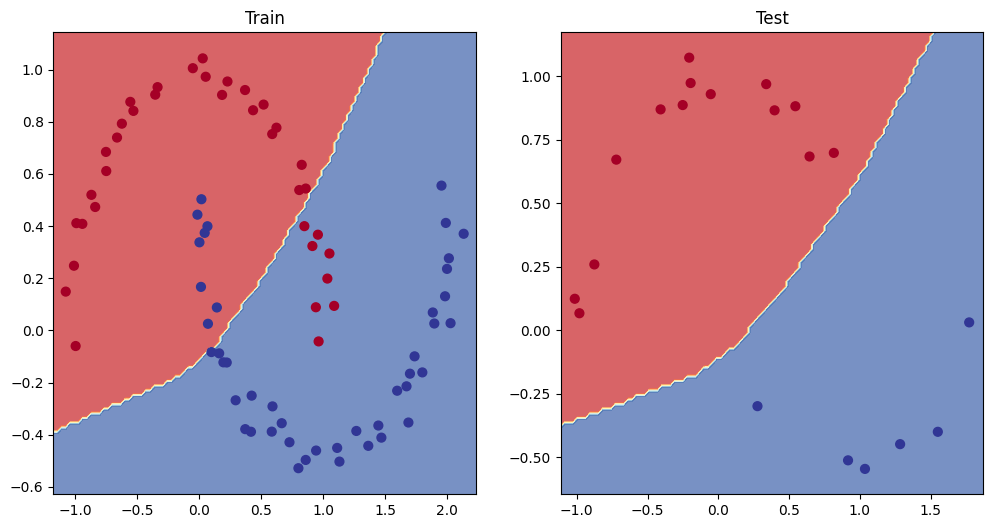

In [92]:
import importlib
import helper_functions

importlib.reload(helper_functions)
from helper_functions import plot_decision_boundary

# Now run your plot
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_1, X_moon_train, y_moon_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_1, X_moon_test, y_moon_test)


### Section 2 of the assignment multi-class dataset

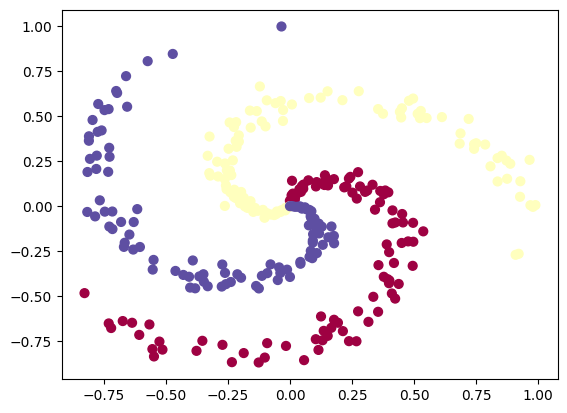

In [96]:
N = 100 # number of points per class
D = 2 # dimensionality
K = 3 # number of classes
X = np.zeros((N*K,D)) # data matrix (each row = single example)
y = np.zeros(N*K, dtype='uint8') # class labels
for j in range(K):
  ix = range(N*j,N*(j+1))
  r = np.linspace(0.0,1,N) # radius
  t = np.linspace(j*4,(j+1)*4,N) + np.random.randn(N)*0.2 # theta
  X[ix] = np.c_[r*np.sin(t), r*np.cos(t)]
  y[ix] = j
# lets visualize the data:
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
plt.show()

In [97]:
X = torch.from_numpy(X).type(torch.float)
y= torch.from_numpy(y).type(torch.float)

print(f"first five values of X: {X[:5]}")
print(f"first five values of y: {y[:5]}")

first five values of X: tensor([[ 0.0000,  0.0000],
        [ 0.0002,  0.0101],
        [ 0.0064,  0.0192],
        [-0.0004,  0.0303],
        [ 0.0193,  0.0355]])
first five values of y: tensor([0., 0., 0., 0., 0.])


In [99]:
X_train, X_test, y_train, y_test = train_test_split(X,
                                                   y,
                                                   test_size=0.2,
                                                   random_state=random_seed)
print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}, y_test: {y_test.shape}")

X_train: torch.Size([240, 2]), y_train: torch.Size([240])
X_test: torch.Size([60, 2]), y_test: torch.Size([60])


In [103]:
class SpiralData(nn.Module):
    def __init__(self, input_features, output_features, hidden_units=8):
        super().__init__()

        self.linear_layer_stack_2 = nn.Sequential(
            nn.Linear(in_features=input_features, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=output_features)
        )

    def forward(self, x):
        return self.linear_layer_stack_2(x)

model_2 = SpiralData(input_features=D,
                    output_features=K,
                    hidden_units=10).to(device)

model_2

SpiralData(
  (linear_layer_stack_2): Sequential(
    (0): Linear(in_features=2, out_features=10, bias=True)
    (1): ReLU()
    (2): Linear(in_features=10, out_features=10, bias=True)
    (3): ReLU()
    (4): Linear(in_features=10, out_features=3, bias=True)
  )
)

In [105]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_2.parameters(),
                        lr=0.001)

In [122]:
epochs = 100

for epoch in range(epochs):
    ### TRAINING
    model_2.train()

    y_train = y_train.type(torch.long)
    y_test = y_test.type(torch.long)
    
    y_logits = model_2(X_train)
    y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1)

    loss = loss_fn(y_logits, y_train)
    acc = accuracy_fn(y_true=y_train,
                     y_pred=y_pred)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    ### TESTING
    model_2.eval()

    with torch.inference_mode():
        test_logits = model_2(X_test)
        test_pred = torch.softmax(test_logits, dim=1).argmax(dim=1)

        loss = loss_fn(test_logits, y_test)
        acc = accuracy_fn(y_true=y_train,
                         y_pred=y_pred)

    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Acc: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.2f}%")

Epoch: 0 | Loss: 0.18443, Acc: 92.08% | Test Loss: 0.40717, Test Acc: 100.00%
Epoch: 10 | Loss: 0.18016, Acc: 92.08% | Test Loss: 0.40717, Test Acc: 100.00%
Epoch: 20 | Loss: 0.17612, Acc: 92.08% | Test Loss: 0.40717, Test Acc: 100.00%
Epoch: 30 | Loss: 0.17220, Acc: 92.50% | Test Loss: 0.40717, Test Acc: 100.00%
Epoch: 40 | Loss: 0.16828, Acc: 92.50% | Test Loss: 0.40717, Test Acc: 100.00%
Epoch: 50 | Loss: 0.16475, Acc: 92.50% | Test Loss: 0.40717, Test Acc: 100.00%
Epoch: 60 | Loss: 0.16125, Acc: 92.50% | Test Loss: 0.40717, Test Acc: 100.00%
Epoch: 70 | Loss: 0.15790, Acc: 92.92% | Test Loss: 0.40717, Test Acc: 100.00%
Epoch: 80 | Loss: 0.15469, Acc: 93.75% | Test Loss: 0.40717, Test Acc: 100.00%
Epoch: 90 | Loss: 0.15157, Acc: 94.17% | Test Loss: 0.40717, Test Acc: 100.00%


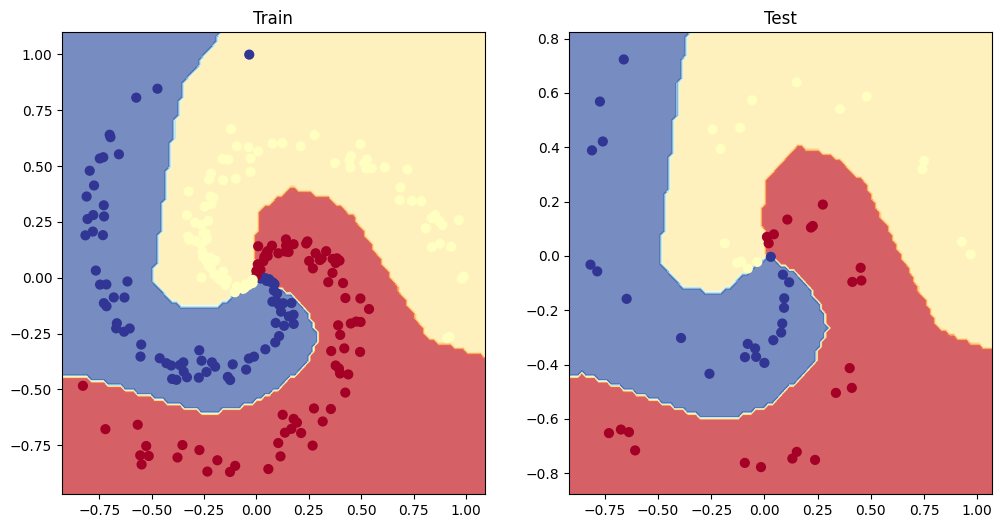

In [123]:
import importlib
import helper_functions

importlib.reload(helper_functions)
from helper_functions import plot_decision_boundary

# Now run your plot
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_2, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_2, X_test, y_test)
